# Reading drilling logs: from the driller's words to a depth to bedrock

**KAI Academy · practice notebook 1.** You will load a borehole register and its drilling logs, find the errors that
every real register has, turn the driller's descriptions into three classes (cover, weathered rock, fresh rock), and
check the log against the recorded depth to bedrock. Then you will do the same on **real, openly licensed records**
from British Columbia, Canada, where the rock is glacial sand, gravel and clay instead of weathered basement.

* **Part A, synthetic register.** `data/practice_boreholes.csv` and `data/practice_logs.csv` are **invented**
  (`make_practice_data.py`, fixed seed). They have the shape of a national borehole register in weathered
  crystalline basement, as in much of East Africa, but no record, place or coordinate is real.
* **Part B, real records.** `data/langley_wells.csv.gz` and `data/langley_lithology.csv.gz`: 4,288 water-supply wells
  in the Township of Langley from GWELLS, Province of British Columbia, under the Open Government Licence – British
  Columbia (see `DATA.md`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

b = pd.read_csv("data/practice_boreholes.csv")
logs = pd.read_csv("data/practice_logs.csv")
print(len(b), "boreholes,", len(logs), "log layers,", logs.SourceID.nunique(), "boreholes with a log")
b.head()

600 boreholes, 2718 log layers, 550 boreholes with a log


,SourceID,District,Easting_m,Northing_m,GroundLevel_masl,YearDrilled,TotalDrilledDepth,DepthToBedRock,StaticWaterLevel,ConstantDischargeYield,Synthetic
0,PRAC-0001,Practice East,23663,15670,1101.8,2001,132.5,87.8,14.9,3.7,True
1,PRAC-0002,Practice West,14321,29100,1077.1,1996,80.3,53.8,12.2,4.2,True
2,PRAC-0003,Practice West,19357,28457,1065.4,2008,48.6,26.5,11.9,1.1,True
3,PRAC-0004,Practice East,39463,12832,1184.5,1988,82.0,33.3,15.9,1.0,True
4,PRAC-0005,Practice West,5438,22853,1015.1,2002,54.8,32.6,34.5,2.5,True


## A1. Check the register before you trust it

Three checks every time: what is missing, what is impossible, and what is in the wrong unit. A water level deeper than
the hole was drilled is impossible; a water level several times the area's typical value may be in feet.

In [2]:
cols = ["TotalDrilledDepth", "DepthToBedRock", "StaticWaterLevel", "ConstantDischargeYield"]
print("missing (share):")
print(b[cols].isna().mean().round(2))
impossible = b[b.StaticWaterLevel > b.TotalDrilledDepth]
med = b.StaticWaterLevel.median()
suspect_feet = b[(b.StaticWaterLevel > 3 * med) & ~b.index.isin(impossible.index)]
print(f"\nwater level deeper than the hole: {len(impossible)}")
print(f"water level more than 3x the median ({med:.1f} m), possibly feet: {len(suspect_feet)}")
suspect_feet[["SourceID", "StaticWaterLevel", "TotalDrilledDepth"]].head(10)

missing (share):
TotalDrilledDepth         0.00
DepthToBedRock            0.17
StaticWaterLevel          0.10
ConstantDischargeYield    0.22
dtype: float64

water level deeper than the hole: 1
water level more than 3x the median (11.1 m), possibly feet: 9


,SourceID,StaticWaterLevel,TotalDrilledDepth
4,PRAC-0005,34.5,54.8
67,PRAC-0068,45.1,60.8
186,PRAC-0187,51.3,103.4
193,PRAC-0194,35.9,81.5
286,PRAC-0287,40.0,76.1
292,PRAC-0293,42.6,55.3
439,PRAC-0440,46.6,50.7
446,PRAC-0447,40.5,50.5
485,PRAC-0486,50.9,55.2


Do not delete suspect rows silently. Flag them, report how many, and test whether your answer changes without them.

In [3]:
b["swl_flag"] = b.index.isin(impossible.index) | b.index.isin(suspect_feet.index)
ok = b[~b.swl_flag]
print(f"median water level: all {b.StaticWaterLevel.median():.1f} m, flagged removed {ok.StaticWaterLevel.median():.1f} m")

median water level: all 11.1 m, flagged removed 10.8 m


## A2. Class the driller's words

Drillers write what they see, in their own words: *murram*, *laterite & clay*, *wthd rock, grey*, *fresh granite*.
A short list of keywords, checked in order, turns them into three classes. Always print what was **not** classed:
that list tells you which keyword is missing.

In [4]:
RULES = [  # checked in order: the first match wins
    ("fresh rock", ["fresh", "hard rock", "massive", "hard grey", "granite gneiss, hard"]),
    ("weathered rock", ["weather", "wthd", "decomposed", "saprolite", "fractur"]),
    ("cover", ["soil", "clay", "laterite", "murram"]),
]

def classify(text):
    t = str(text).lower()
    for cls, words in RULES:
        if any(w in t for w in words):
            return cls
    return "not classed"

logs["class"] = logs.Description.map(classify)
print(logs["class"].value_counts())
print("\nnot classed:", sorted(logs.loc[logs["class"] == "not classed", "Description"].unique()))

class
cover             1100
weathered rock    1068
fresh rock         550
Name: count, dtype: int64

not classed: []


## A3. Depth to bedrock from the log, against the recorded value

The top of the first *fresh rock* layer is the log's depth to bedrock. Compare it with the register's
`DepthToBedRock`. Where they disagree, one of them is wrong, and it is worth knowing which before you map either.

461 boreholes with both; median difference -0.10 m; within 1 m: 60%


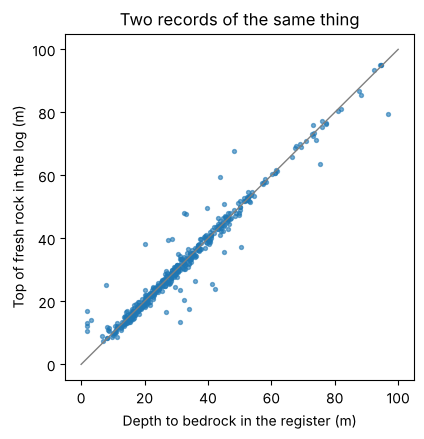

In [5]:
top_fresh = logs[logs["class"] == "fresh rock"].groupby("SourceID").From_m.min().rename("bedrock_from_log")
cmp = b.set_index("SourceID").join(top_fresh, how="inner").dropna(subset=["DepthToBedRock"])
d = cmp.bedrock_from_log - cmp.DepthToBedRock
print(f"{len(cmp)} boreholes with both; median difference {d.median():+.2f} m; within 1 m: {(d.abs() <= 1).mean():.0%}")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(cmp.DepthToBedRock, cmp.bedrock_from_log, s=8, alpha=0.6)
ax.plot([0, 100], [0, 100], color="grey", lw=1)
ax.set_xlabel("Depth to bedrock in the register (m)"); ax.set_ylabel("Top of fresh rock in the log (m)")
ax.set_title("Two records of the same thing"); plt.show()

## A4. Where is the aquifer thick, and does it pay?

In weathered basement the water sits in the weathered and fractured zone. Its saturated thickness (from the water
level down to bedrock) is the first thing to map before siting a borehole.

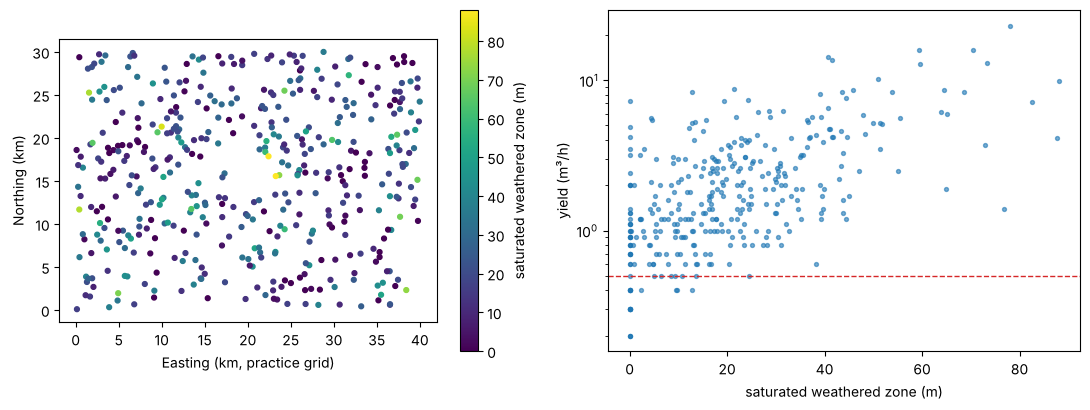

             share ≥ 0.5 m³/h  size
saturated_m                        
(0, 5]                   0.96    25
(5, 10]                  0.94    35
(10, 20]                 0.99    80
(20, 40]                 1.00   112
(40, 100]                1.00    45


In [6]:
ok = b[~b.swl_flag].dropna(subset=["DepthToBedRock", "StaticWaterLevel"]).copy()
ok["saturated_m"] = (ok.DepthToBedRock - ok.StaticWaterLevel).clip(lower=0)
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
sc = axs[0].scatter(ok.Easting_m / 1000, ok.Northing_m / 1000, c=ok.saturated_m, s=12, cmap="viridis")
plt.colorbar(sc, ax=axs[0], label="saturated weathered zone (m)")
axs[0].set_xlabel("Easting (km, practice grid)"); axs[0].set_ylabel("Northing (km)"); axs[0].set_aspect("equal")
y = ok.dropna(subset=["ConstantDischargeYield"])
axs[1].scatter(y.saturated_m, y.ConstantDischargeYield, s=8, alpha=0.6)
axs[1].set_yscale("log"); axs[1].axhline(0.5, color="tab:red", lw=1, ls="--")
axs[1].set_xlabel("saturated weathered zone (m)"); axs[1].set_ylabel("yield (m³/h)")
plt.tight_layout(); plt.show()
bins = pd.cut(y.saturated_m, [0, 5, 10, 20, 40, 100])
print((y.ConstantDischargeYield >= 0.5).groupby(bins, observed=True).agg(["mean", "size"]).rename(columns={"mean": "share ≥ 0.5 m³/h"}).round(2))

**Your turn.** (1) Add the keyword your class list missed and rerun A2. (2) Repeat A4 for a motorised pump target
of 3 m³/h: how does the success rate change with saturated thickness? (3) Which district would you survey first?

## B. The same steps on real records: Langley, British Columbia

Real wells, real drillers' words, real gaps. The geology is different (glacial and glaciomarine sand, gravel, clay and
till over deep bedrock), so the classes are different: **aquifer** (sand, gravel) and **aquitard** (clay, silt,
till). Everything else carries over.

In [7]:
w = pd.read_csv("data/langley_wells.csv.gz")
lith = pd.read_csv("data/langley_lithology.csv.gz")
print(len(w), "wells,", len(lith), "layers")
print(w[["depth_m", "swl_m", "yield_m3h", "bedrock_m"]].describe().round(1))

4288 wells, 30492 layers
       depth_m   swl_m  yield_m3h  bedrock_m
count   4192.0  3252.0     3771.0       80.0
mean      48.4    20.1        6.2       20.2
std       34.1    16.1       16.9       34.8
min        0.0     0.0        0.0        0.0
25%       23.2     6.7        1.1        2.4
50%       42.1    16.2        2.3        9.0
75%       66.3    30.5        5.7       17.6
max      353.0   140.2      545.0      194.5


In [8]:
GL_RULES = [
    ("aquitard", ["clay", "silt", "till", "hardpan", "mud"]),
    ("aquifer", ["sand", "gravel", "w.b.", "water bearing"]),
    ("bedrock", ["bedrock", "sandstone", "shale", "rock"]),
]

def gclass(text):
    t = str(text).lower()
    for cls, words in GL_RULES:
        if any(x in t for x in words):
            return cls
    return "not classed"

lith["class"] = lith.description.map(gclass)
print(lith["class"].value_counts())
print("\nmost common unclassed words:", lith.loc[lith["class"] == "not classed", "description"].str.lower().value_counts().head(8).to_dict())

class
aquitard       15391
aquifer         9786
not classed     5097
bedrock          218
Name: count, dtype: int64

most common unclassed words: {'top soil': 591, 'topsoil': 196, 'fill': 127, 'dirt': 109, 'soil': 58, 'boulder': 58, 'boulders': 24, 'existing 6" drilled well': 22}


**Your turn.** The unclassed list is mostly *top soil*, *fill* and *dirt*. Add a `cover` class for them and rerun.

Note the order of the rules: *"sand and clay"* is classed as aquitard because clay is checked first. Change the
order and see how many layers move. In a real study you would write that choice down.

               share ≥ 0.5 m³/h  size
sand_share                           
(-0.001, 0.2]              0.79  1529
(0.2, 0.4]                 0.93   622
(0.4, 0.6]                 0.91   438
(0.6, 0.8]                 0.89   332
(0.8, 1.0]                 0.78   738


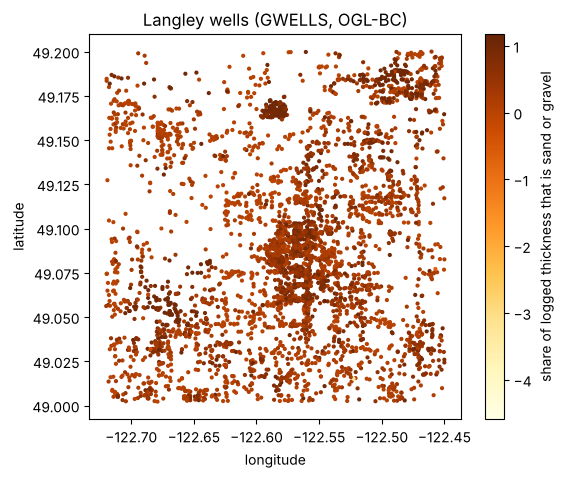

In [9]:
thick = (lith.assign(t=lith.bottom_m - lith.top_m)
         .pivot_table(index="well_id", columns="class", values="t", aggfunc="sum", fill_value=0))
ww = w.set_index("well_id").join(thick, how="inner")
ww["sand_share"] = ww.get("aquifer", 0) / (ww.get("aquifer", 0) + ww.get("aquitard", 0)).replace(0, np.nan)
yy = ww.dropna(subset=["yield_m3h", "sand_share"])
bins = pd.cut(yy.sand_share, [0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)
print((yy.yield_m3h >= 0.5).groupby(bins, observed=True).agg(["mean", "size"]).rename(columns={"mean": "share ≥ 0.5 m³/h"}).round(2))
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(ww.lon, ww.lat, c=ww.sand_share, s=4, cmap="YlOrBr")
plt.colorbar(sc, label="share of logged thickness that is sand or gravel")
ax.set_title("Langley wells (GWELLS, OGL-BC)"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); plt.show()

## What to take away

* Check the register first: gaps, impossible values, units.
* Class the driller's words with rules you can read and print what they miss.
* Compare two records of the same thing before mapping either.
* The method carries over from basement to glacial sediments; the classes and the skill do not, so test again on
  local records. KAI's drilling-odds lab runs that blind test on these Langley wells:
  [Heterogeneity Lab](https://kai-water.charkaks0.workers.dev/drilling-lab).

*Part A is synthetic practice data. Part B: GWELLS, Province of British Columbia, Open Government Licence – British
Columbia. Ground elevations from the Copernicus DEM GLO-30 (© DLR e.V. 2010–2014 and © Airbus Defence and Space GmbH
2014–2018, provided under COPERNICUS by the European Union and ESA).*